# ***NOTEBOOK 1: "Data Exploration"***

### ***Important Question that Notebook 1 will help us understand:***

## **- Why do we need Hidden Markov Models?**

**Answer:**

#### **✅Financial markets exhibit fat tails, volatility clustering, dynamic correlations, and time-varying statistical properties that violate the assumptions of many classical financial models.**

#### **✅These observations suggest that asset returns are generated under multiple latent market environments rather than a single stationary process.**

#### **✅Since these environments cannot be directly observed but instead reveal themselves through patterns in returns, volatility, and cross-asset behavior, Hidden Markov Models provide a principled probabilistic framework for inferring hidden market regimes and enabling adaptive portfolio allocation.**




### ***1. Data Collection***

### ***Library Imports***

**This cell imports all the necessary libraries for data acquisition, manipulation, and visualization, including `yfinance` for financial data, `pandas` for data structures, `numpy` for numerical operations, and `matplotlib` for plotting.**

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("ggplot")

### ***Define Tickers***

**This cell defines a list of ticker symbols for the financial instruments we intend to analyze. These symbols will be used to fetch historical data.**

In [ ]:
TICKERS = ["SPY", "TLT", "GLD", "^VIX"]

### ***Download Historical Prices***

**This cell uses the `yfinance` library to download the historical 'Close' prices for the defined tickers. The data is fetched from '2005-01-01' up to '2026-06-30' and `auto_adjust=True` ensures the prices are adjusted for splits and dividends. The first few rows of the downloaded data are displayed.**

In [ ]:
prices = yf.download(
    TICKERS,
    start="2005-01-01",
    end="2026-06-30",
    auto_adjust=True,
    progress=False)["Close"]

prices.head()

Ticker,GLD,SPY,TLT,^VIX
Date,,,,
2005-01-03,43.020000,81.174599,44.059822,14.08
2005-01-04,42.740002,80.182693,43.598083,13.98
2005-01-05,42.669998,79.629379,43.831398,14.09
2005-01-06,42.150002,80.034248,43.861198,13.58
2005-01-07,41.840000,79.919548,43.960510,13.49


### ***Display Data Information***

**This cell provides a concise summary of the DataFrame, including the data types of each column, the number of non-null values, and memory usage. This helps in identifying missing values and understanding the data structure.**

In [ ]:
prices.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5406 entries, 2005-01-03 to 2026-06-29
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   GLD     5405 non-null   float64
 1   SPY     5405 non-null   float64
 2   TLT     5405 non-null   float64
 3   ^VIX    5406 non-null   float64
dtypes: float64(4)
memory usage: 211.2 KB


### ***Identify Rows with Missing Values***

**This cell filters and displays any rows in the `prices` DataFrame that contain at least one missing (NaN) value. This is useful for pinpointing specific dates or entries where data might be incomplete.**

In [ ]:
prices[prices.isna().any(axis=1)]

Ticker,GLD,SPY,TLT,^VIX
Date,,,,
2026-05-25,NaN,NaN,NaN,16.59


### ***Descriptive Statistics***

**This cell generates descriptive statistics for each ticker's closing prices, providing insights into the central tendency, dispersion, and shape of the distribution, such as mean, standard deviation, min, max, and quartiles.**

In [ ]:
prices.describe()

Ticker,GLD,SPY,TLT,^VIX
count,5405.000000,5405.000000,5405.000000,5406.000000
mean,143.377530,235.101535,82.284628,19.150745
std,73.444360,169.597794,23.602808,8.567884
min,41.259998,49.680573,43.579067,9.140000
25%,107.980003,98.558846,60.680141,13.500000
50%,125.839996,173.145325,84.663445,16.825000
75%,167.809998,350.743134,95.710526,22.072500
max,495.899994,757.618225,142.699554,82.690002


### ***Display Dataset Shape***

**This cell prints the number of rows and columns in the `prices` DataFrame, giving a quick overview of the dataset's dimensions.**

In [ ]:
print("Dataset Shape:")
prices.shape

Dataset Shape:


(5406, 4)

### ***Display Date Range***

**This cell prints the earliest and latest dates present in the DataFrame's index, indicating the overall time period covered by the historical data.**

In [ ]:
print("Start Date:", prices.index.min())
print("End Date:", prices.index.max())

Start Date: 2005-01-03 00:00:00
End Date: 2026-06-29 00:00:00


### ***2. Data Cleaning***

### Check for Null Values
This cell calculates and displays the count of missing (NaN) values for each column in the `prices` DataFrame. This helps to identify which tickers have incomplete data.

In [ ]:
# NULL Values
print(prices.isna().sum())

Ticker
GLD     1
SPY     1
TLT     1
^VIX    0
dtype: int64


### ***Drop Rows with Missing Values***

**This cell removes any rows from the `prices` DataFrame that contain missing values across any of its columns. This ensures a clean dataset for further analysis where all entries are complete.**

In [ ]:
prices = prices.dropna()

### ***Verify Null Values After Cleaning***

**This cell re-checks for null values after the `dropna()` operation, confirming that all missing data has been successfully removed from the `prices` DataFrame.**

In [ ]:
# NULL values after
print(prices.isna().sum())

Ticker
GLD     0
SPY     0
TLT     0
^VIX    0
dtype: int64


### ***Display Dataset Shape After Cleaning***

**This cell prints the updated shape of the `prices` DataFrame after dropping rows with missing values, showing the new dimensions of the cleaned dataset.**

In [ ]:
print("Dataset Shape After Cleaning:")
print(prices.shape)

Dataset Shape After Cleaning:
(5405, 4)


### ***Check for Duplicated Index Values***

**This cell checks if there are any duplicate dates in the DataFrame's index. Duplicate index values can cause issues in time-series analysis, so this step ensures the index is unique.**

In [ ]:
print(prices.index.duplicated().sum())

0


### ***Plot Adjusted Closing Prices***

**This cell generates a time-series plot of the adjusted closing prices for all tickers. This visualization helps in understanding the price trends and overall performance of the assets over time.**

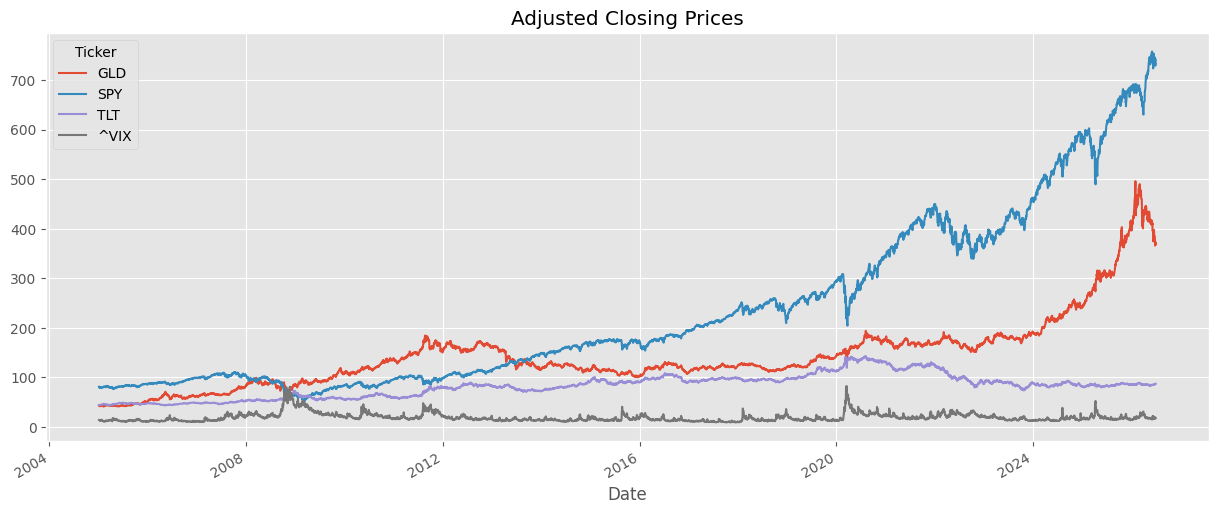

In [ ]:
import matplotlib.pyplot as plt

prices.plot(figsize=(15,6))

plt.title("Adjusted Closing Prices")

plt.show()

### ***3. Log Returns***

### ***Compute Log Returns***

**This cell calculates the log returns of the adjusted closing prices. Log returns are often preferred in financial analysis due to their additive property and better statistical properties compared to simple returns. Rows with NaN values (from the `shift(1)` operation) are then dropped.**

In [ ]:
# Computing Log returns
log_returns = np.log(prices / prices.shift(1))
log_returns = log_returns.dropna()
log_returns.head()

Ticker,GLD,SPY,TLT,^VIX
Date,,,,
2005-01-04,-0.006530,-0.012295,-0.010535,-0.007128
2005-01-05,-0.001639,-0.006925,0.005337,0.007838
2005-01-06,-0.012261,0.005072,0.000680,-0.036867
2005-01-07,-0.007382,-0.001434,0.002262,-0.006649
2005-01-10,0.002626,0.004717,0.001580,-0.019462


### ***Descriptive Statistics of Log Returns***

**This cell provides descriptive statistics for the log returns of each ticker. This helps in understanding the central tendency, volatility, and distribution of the returns.**

In [ ]:
log_returns.describe()

Ticker,GLD,SPY,TLT,^VIX
count,5404.000000,5404.000000,5404.000000,5404.000000
mean,0.000397,0.000409,0.000126,0.000042
std,0.011489,0.011951,0.009182,0.075746
min,-0.108412,-0.115887,-0.069011,-0.442449
25%,-0.005148,-0.003948,-0.005298,-0.041583
50%,0.000581,0.000717,0.000439,-0.006268
75%,0.006317,0.005790,0.005478,0.034427
max,0.106974,0.135578,0.072503,0.768245


### ***4. Distribution Analysis***

### ***Plot Daily Log Returns***

**This cell generates a time-series plot of the daily log returns for all tickers. This plot visualizes the daily fluctuations in returns and can help in identifying periods of high volatility.**

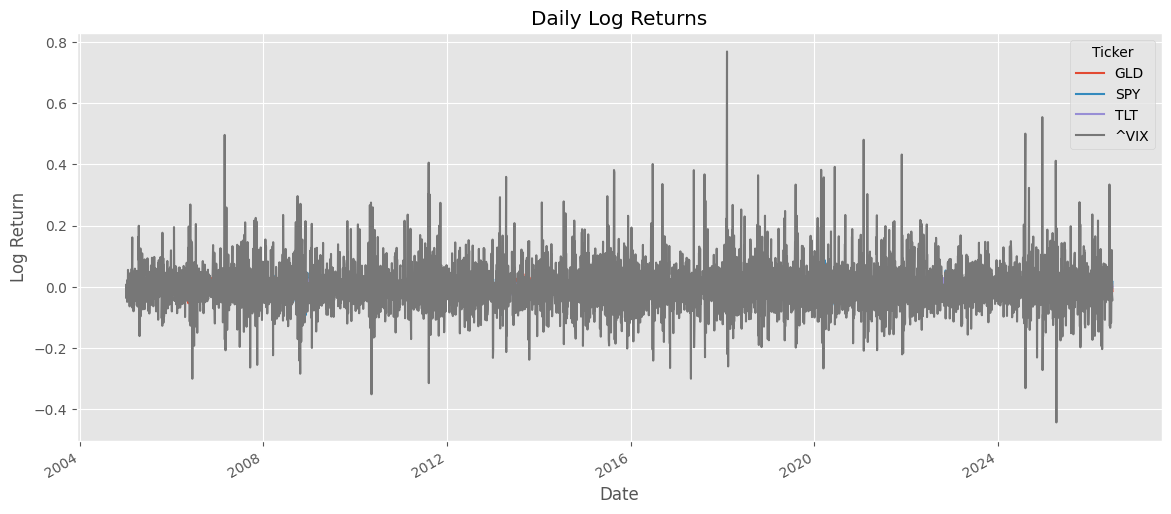

In [ ]:
log_returns.plot(
    figsize=(14,6),
    title="Daily Log Returns")

plt.xlabel("Date")
plt.ylabel("Log Return")
plt.show()

### ***Histograms of Daily Log Returns***

**This cell creates histograms for the daily log returns of each ticker. The histograms show the distribution of returns, allowing for visual inspection of their symmetry and concentration.**

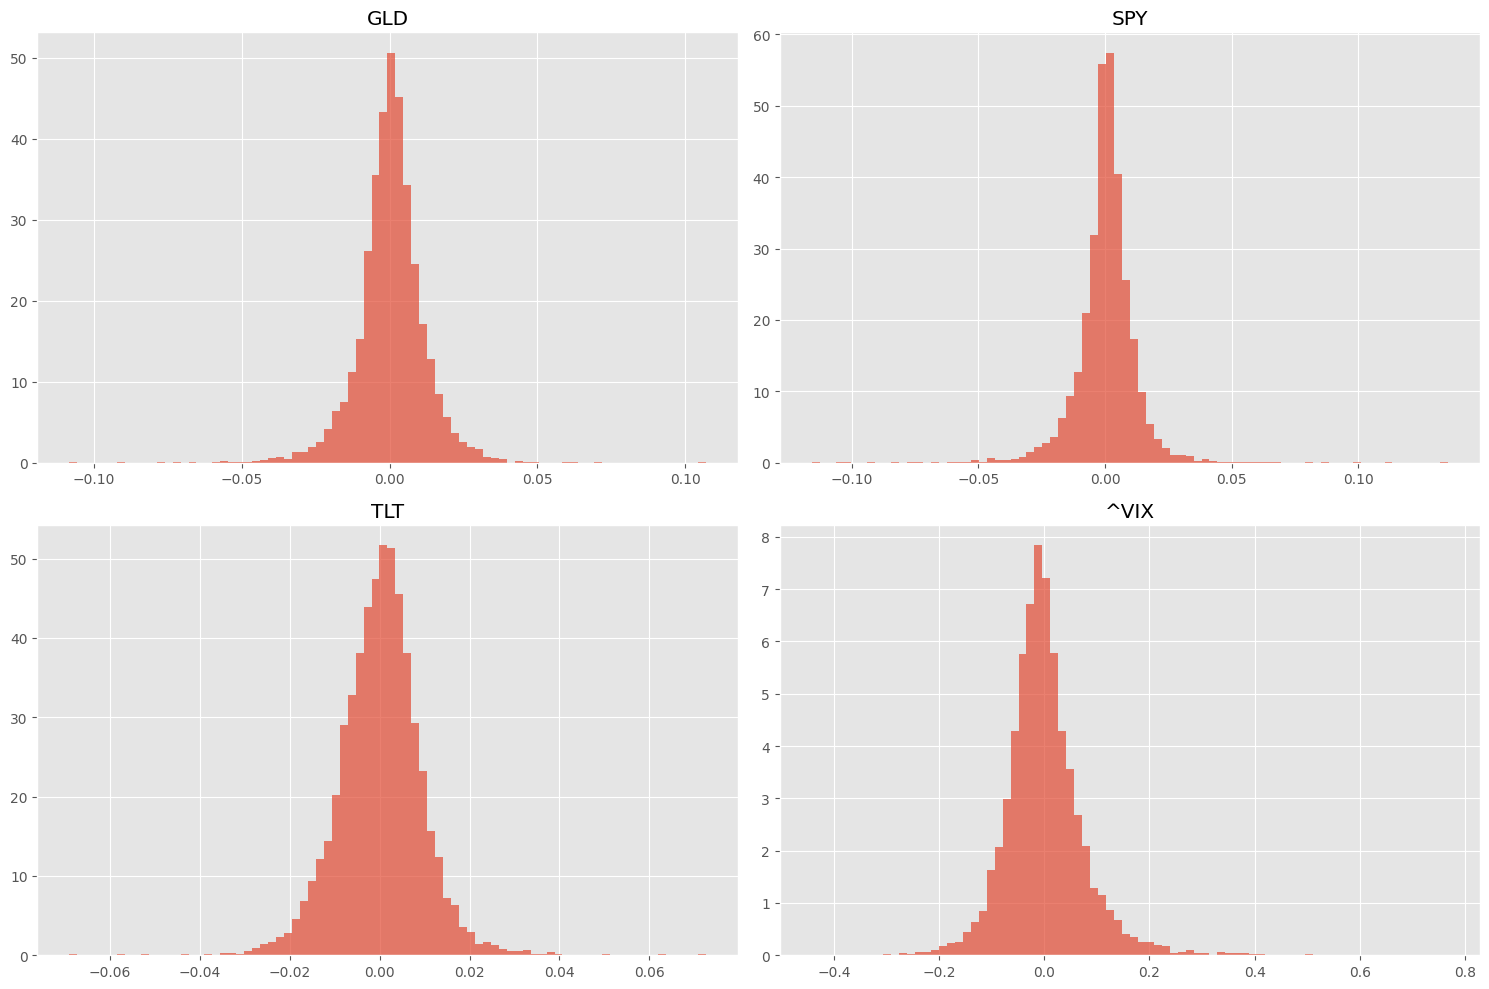

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

assets = log_returns.columns

for ax, asset in zip(axes.flatten(), assets):

    ax.hist(
        log_returns[asset],
        bins=80,
        density=True,
        alpha=0.7)

    ax.set_title(asset)

plt.tight_layout()
plt.show()

### ***Calculate Skewness***

**This cell calculates the skewness of the log returns for each ticker. Skewness measures the asymmetry of the return distribution, indicating whether returns are concentrated on one side of the mean.**

In [ ]:
print("Skewness\n")
print(log_returns.skew())

Skewness

Ticker
GLD    -0.459151
SPY    -0.304261
TLT     0.003073
^VIX    1.034395
dtype: float64


### ***Calculate Kurtosis***

**This cell calculates the kurtosis of the log returns for each ticker. Kurtosis measures the 'tailedness' of the return distribution, indicating the presence of extreme values or outliers compared to a normal distribution.**

In [ ]:
print("Kurtosis\n")
print(log_returns.kurtosis())

Kurtosis

Ticker
GLD      6.755672
SPY     14.691710
TLT      3.448356
^VIX     6.494648
dtype: float64


### ***Compare Log Returns to Normal Distribution***

**This cell generates histograms of the log returns and overlays a fitted normal distribution curve for each ticker. This visual comparison helps in assessing how well the actual return distributions conform to a normal distribution, which is a common assumption in many financial models.**

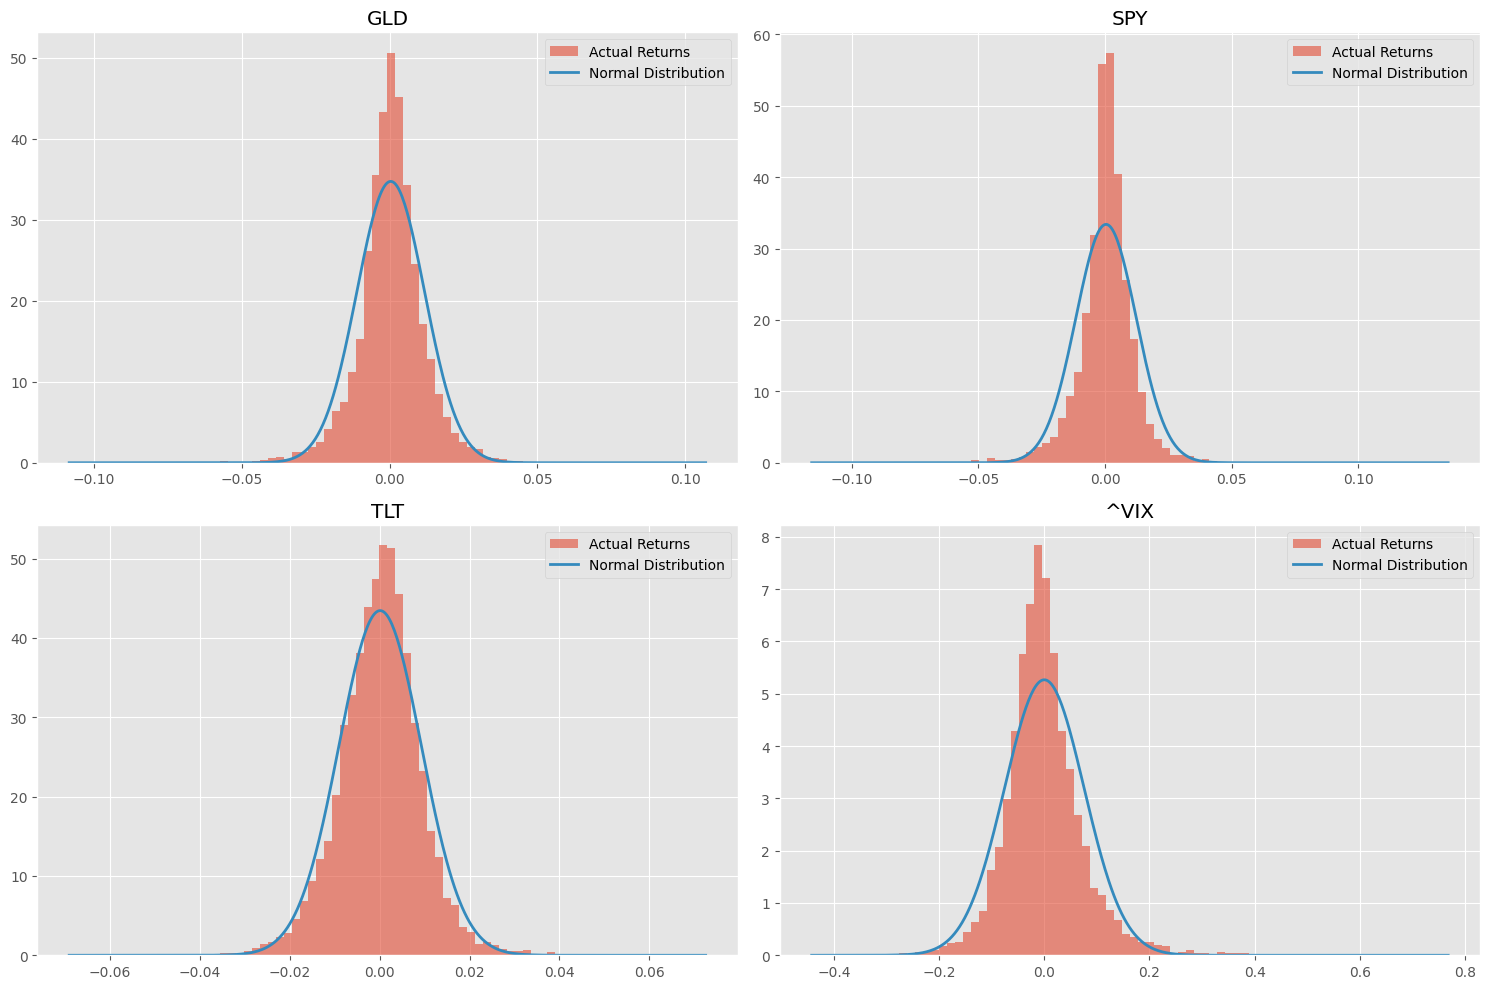

In [ ]:
from scipy.stats import norm

fig, axes = plt.subplots(2,2, figsize=(15,10))

for ax, asset in zip(axes.flatten(), log_returns.columns):

    data = log_returns[asset]

    mu = data.mean()

    sigma = data.std()

    ax.hist(data,
        bins=80,
        density=True,
        alpha=0.6,
        label="Actual Returns")

    x = np.linspace(data.min(), data.max(), 500)

    ax.plot(x, norm.pdf(x, mu, sigma), linewidth=2,
        label="Normal Distribution")

    ax.set_title(asset)

    ax.legend()
plt.tight_layout()
plt.show()

### ***5. Volatility Clustering***

### ***Rolling Annualized Volatility (SPY)***

**This cell calculates and plots the 63-day rolling annualized volatility for SPY. Rolling volatility helps in understanding how the risk of an asset changes over time.**

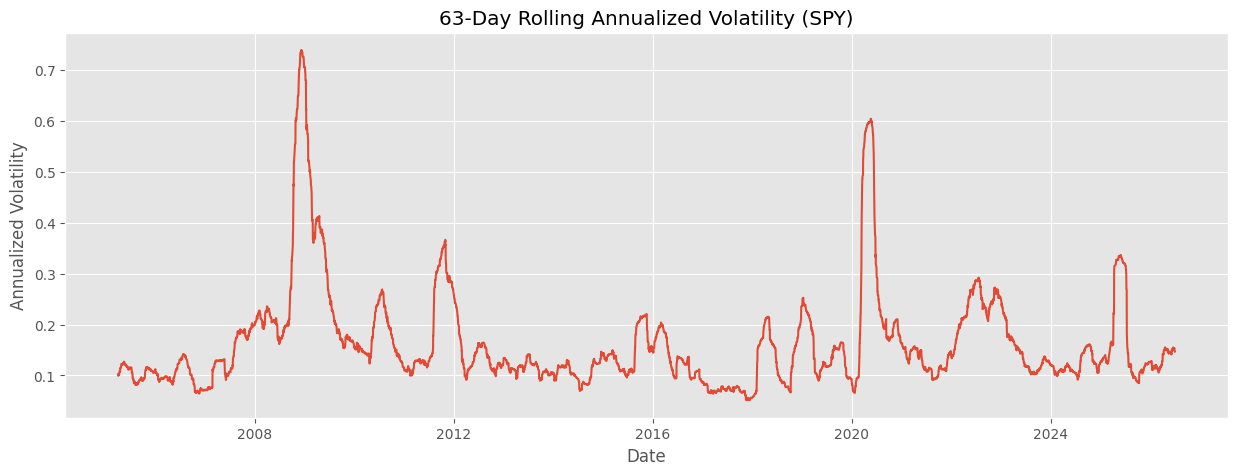

In [ ]:
rolling_vol = log_returns["SPY"].rolling(window=63).std() * np.sqrt(252)

plt.figure(figsize=(15,5))
plt.plot(rolling_vol)
plt.title("63-Day Rolling Annualized Volatility (SPY)")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.grid(True)
plt.show()

### ***Rolling Annualized Volatility (TLT)***

**This cell calculates and plots the 63-day rolling annualized volatility for TLT. Rolling volatility helps in understanding how the risk of an asset changes over time.**

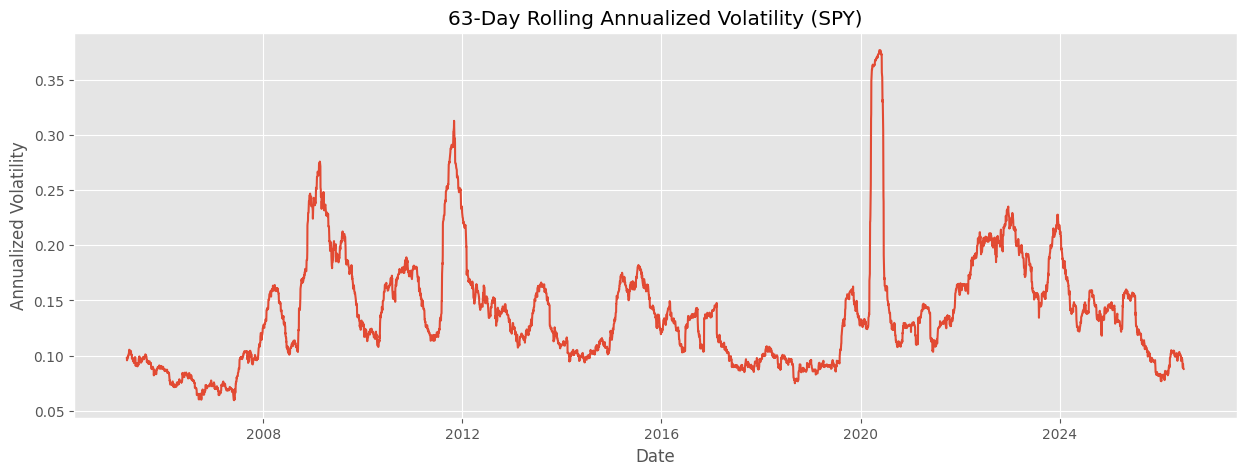

In [ ]:
rolling_vol = log_returns["TLT"].rolling(window=63).std() * np.sqrt(252)

plt.figure(figsize=(15,5))
plt.plot(rolling_vol)
plt.title("63-Day Rolling Annualized Volatility (TLT)")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.grid(True)
plt.show()

### ***Rolling Annualized Volatility (GLD)***

**This cell calculates and plots the 63-day rolling annualized volatility for GLD. Rolling volatility helps in understanding how the risk of an asset changes over time.**

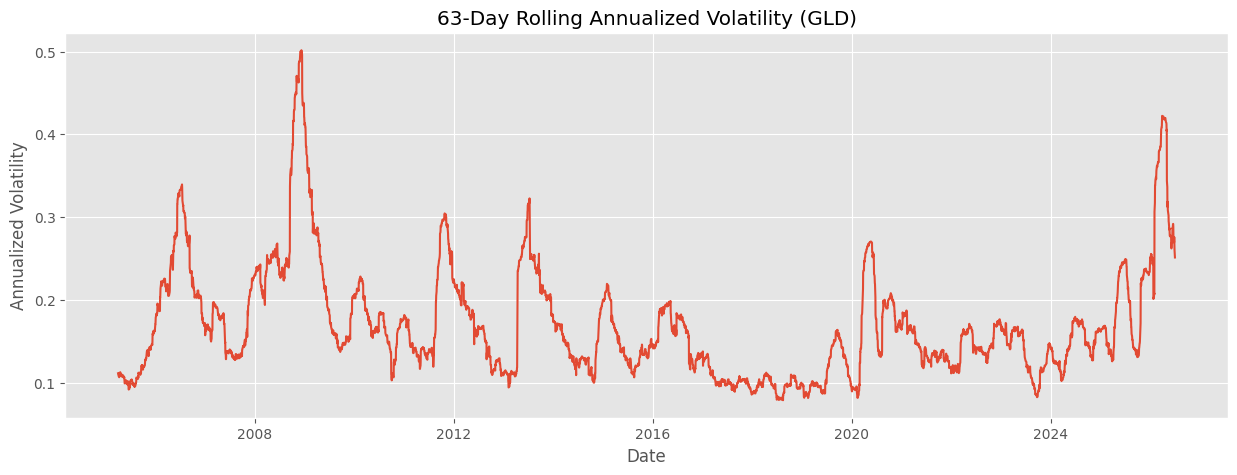

In [ ]:
rolling_vol = log_returns["GLD"].rolling(window=63).std() * np.sqrt(252)

plt.figure(figsize=(15,5))
plt.plot(rolling_vol)
plt.title("63-Day Rolling Annualized Volatility (GLD)")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.grid(True)
plt.show()

### ***Absolute Daily Returns (SPY)***

**This cell plots the absolute values of the daily log returns for SPY. This can highlight periods of high volatility, as large absolute returns (positive or negative) indicate significant price movements.**

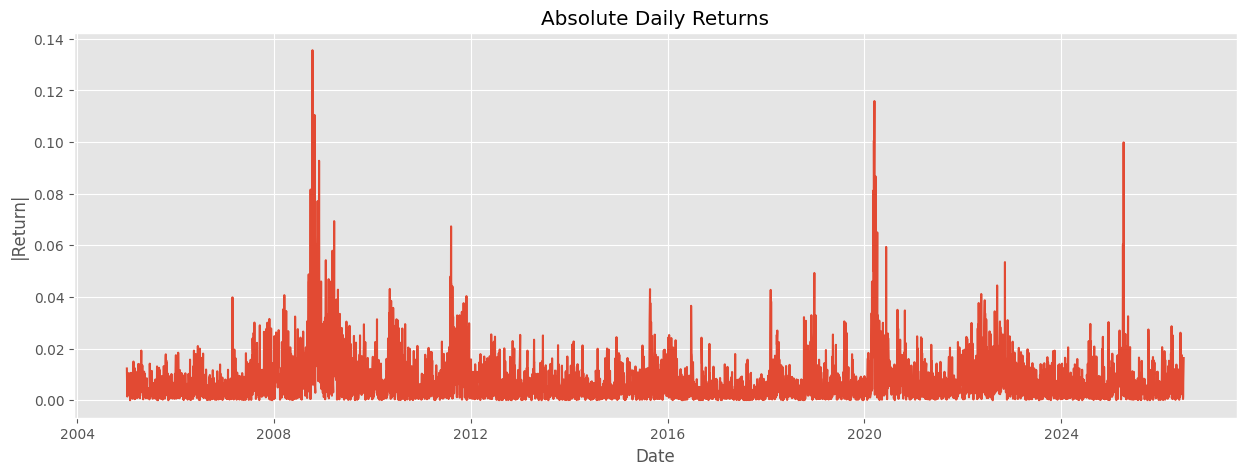

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(log_returns["SPY"].abs())
plt.title("Absolute Daily Returns")
plt.xlabel("Date")
plt.ylabel("|Return|")
plt.grid(True)
plt.show()

### ***Squared Daily Returns (SPY)***

**This cell plots the squared daily log returns for SPY. Squared returns are often used as a proxy for volatility, as they emphasize larger price changes and are always non-negative.**

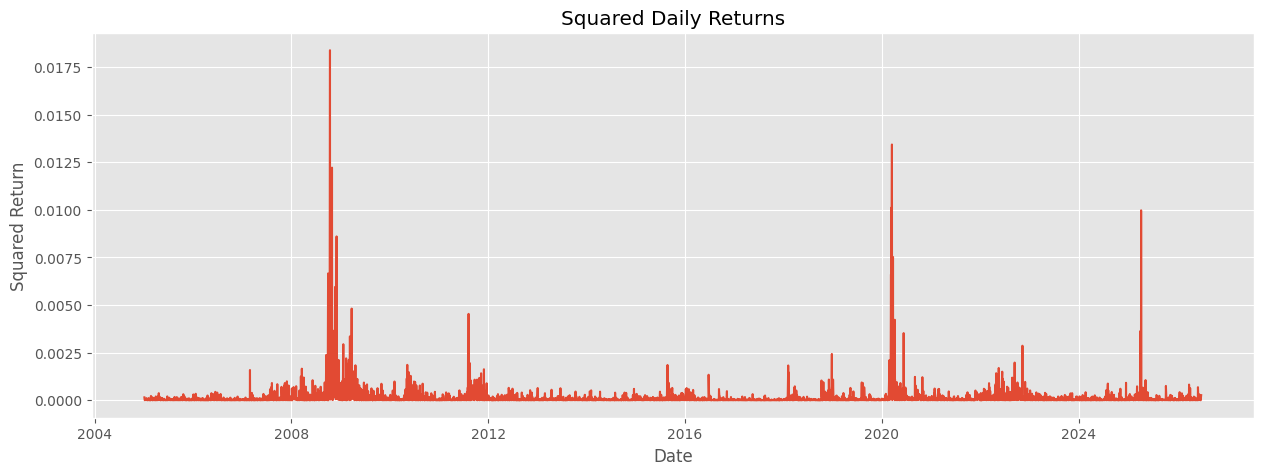

In [ ]:
plt.figure(figsize=(15,5))

plt.plot(log_returns["SPY"]**2)
plt.title("Squared Daily Returns")
plt.xlabel("Date")
plt.ylabel("Squared Return")
plt.grid(True)
plt.show()

### ***6. Dynamic Correlation***

### ***Autocorrelation of Absolute Returns (SPY)***

**This cell plots the Autocorrelation Function (ACF) of the absolute daily log returns for SPY. Significant autocorrelation in absolute (or squared) returns is a hallmark of volatility clustering, where periods of high volatility tend to be followed by periods of high volatility, and vice versa.**

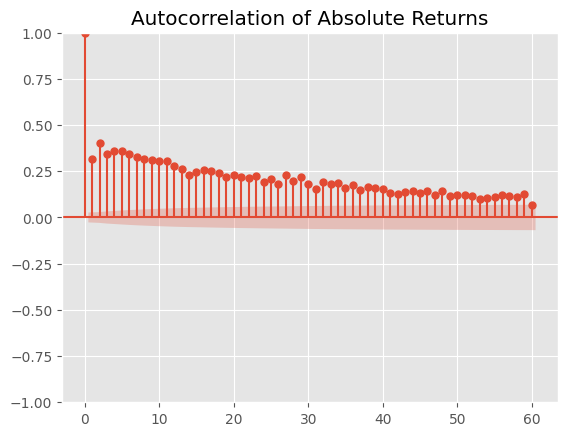

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(log_returns["SPY"].abs().dropna(),
    lags=60)

plt.title("Autocorrelation of Absolute Returns")

plt.show()

### ***Correlation Matrix Calculation***

**This cell calculates the pairwise correlation matrix of the daily log returns for all tickers. The correlation matrix shows the linear relationship between the returns of different assets.**

In [ ]:
corr_matrix = log_returns.corr()
corr_matrix

Ticker,GLD,SPY,TLT,^VIX
Ticker,,,,
GLD,1.000000,0.065152,0.156297,-0.048222
SPY,0.065152,1.000000,-0.299677,-0.741236
TLT,0.156297,-0.299677,1.000000,0.233898
^VIX,-0.048222,-0.741236,0.233898,1.000000


### ***Correlation Matrix Heatmap***

**This cell visualizes the correlation matrix using a heatmap. The heatmap provides a quick and intuitive way to see the strength and direction of the correlation between asset returns.**

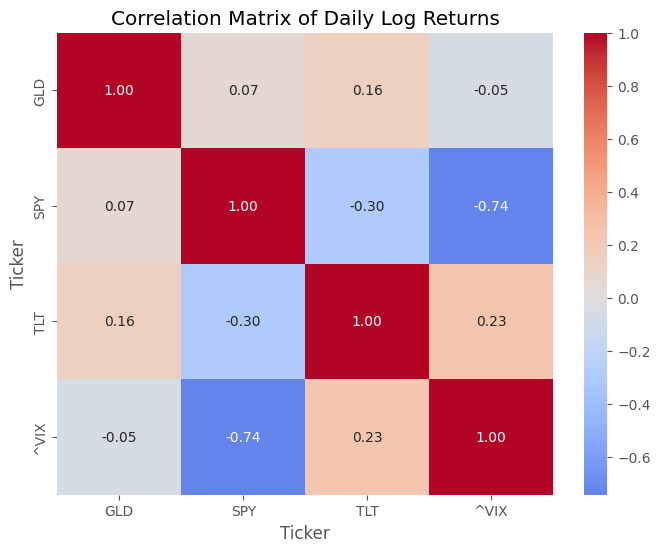

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f")

plt.title("Correlation Matrix of Daily Log Returns")
plt.show()

### ***Rolling Correlation Calculation (SPY vs TLT)***

**This cell calculates the 63-day rolling correlation between the daily log returns of SPY and TLT. Rolling correlation helps to understand how the relationship between these two assets changes over time.**

In [ ]:
rolling_corr = (
    log_returns["SPY"]
    .rolling(window=63)
    .corr(log_returns["TLT"]))

### ***Rolling Correlation Plot (SPY vs TLT)***

**This cell plots the 63-day rolling correlation between SPY and TLT. This visualization helps in observing dynamic changes in their relationship, which can be crucial for portfolio diversification and risk management.**

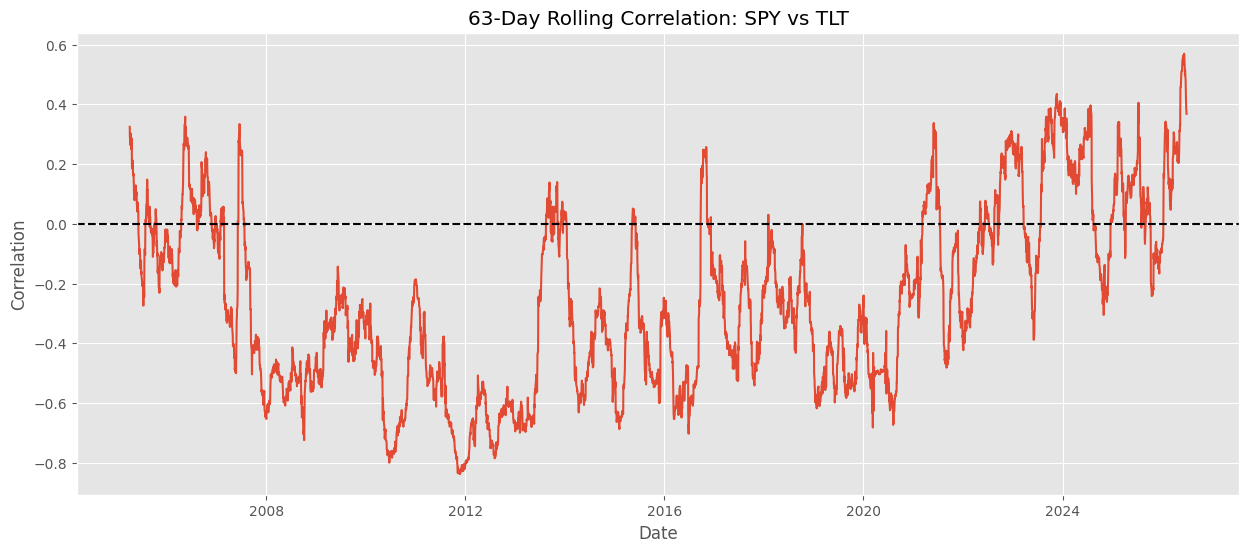

In [ ]:
plt.figure(figsize=(15,6))

plt.plot(rolling_corr, linewidth=1.5)

plt.axhline(0, linestyle="--", color="black")

plt.title("63-Day Rolling Correlation: SPY vs TLT")
plt.xlabel("Date")
plt.ylabel("Correlation")
plt.grid(True)
plt.show()

### ***7. Stationarity***

### ***Rolling Mean of SPY Log Returns***

**This cell calculates and plots the 252-day rolling mean of SPY's daily log returns. The rolling mean helps to visualize changes in the average return over a longer period, indicating potential trends in the asset's performance.**

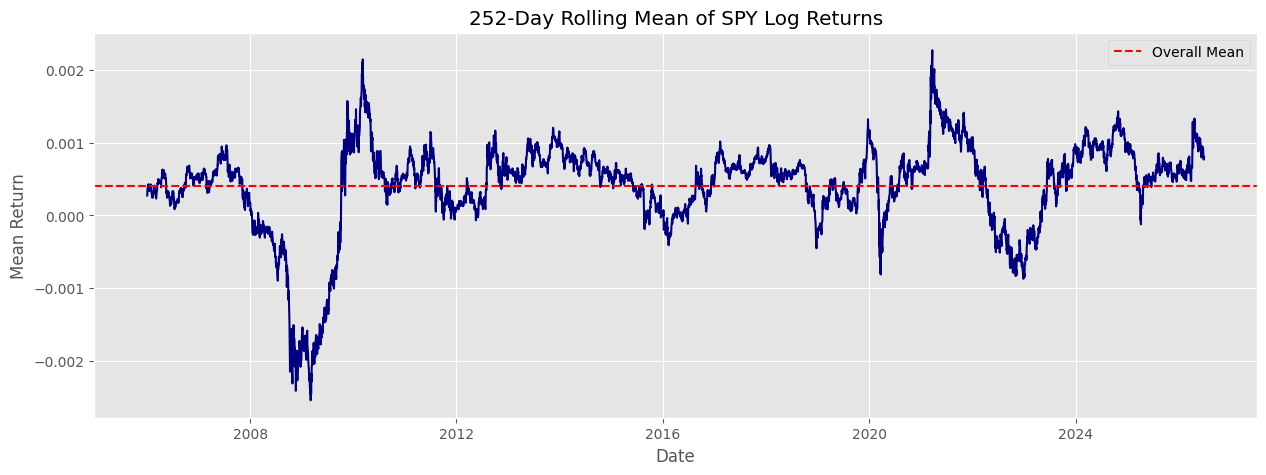

In [ ]:
rolling_mean = log_returns["SPY"].rolling(window=252).mean()

plt.figure(figsize=(15,5))

plt.plot(rolling_mean, color="navy")

plt.axhline(
    rolling_mean.mean(),
    color="red",
    linestyle="--",
    label="Overall Mean")
plt.title("252-Day Rolling Mean of SPY Log Returns")
plt.xlabel("Date")
plt.ylabel("Mean Return")
plt.legend()
plt.grid(True)
plt.show()

### ***Rolling Variance of SPY Log Returns***

**This cell calculates and plots the 252-day rolling variance of SPY's daily log returns. The rolling variance provides insights into how the volatility of the asset changes over time, highlighting periods of increased or decreased risk.**

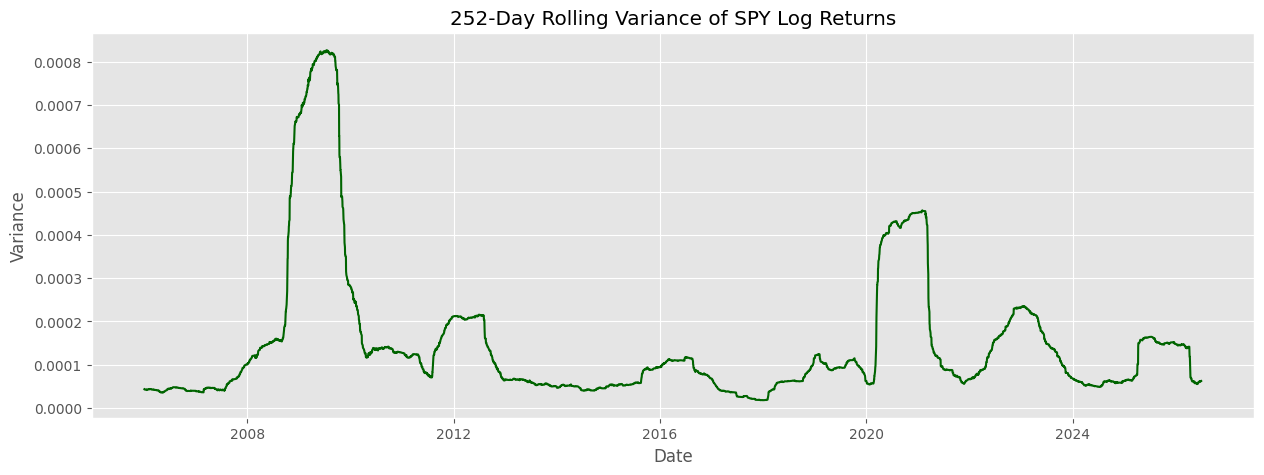

In [ ]:
rolling_var = log_returns["SPY"].rolling(window=252).var()

plt.figure(figsize=(15,5))
plt.plot(rolling_var, color="darkgreen")
plt.title("252-Day Rolling Variance of SPY Log Returns")
plt.xlabel("Date")
plt.ylabel("Variance")
plt.grid(True)
plt.show()

### ***Combined Rolling Mean and Variance Plots (SPY)***

**This cell combines the plots of the 252-day rolling mean and rolling variance for SPY's log returns into a single figure. This allows for a direct comparison of the dynamic behavior of both the central tendency and dispersion of returns over time, which is essential for assessing stationarity.**

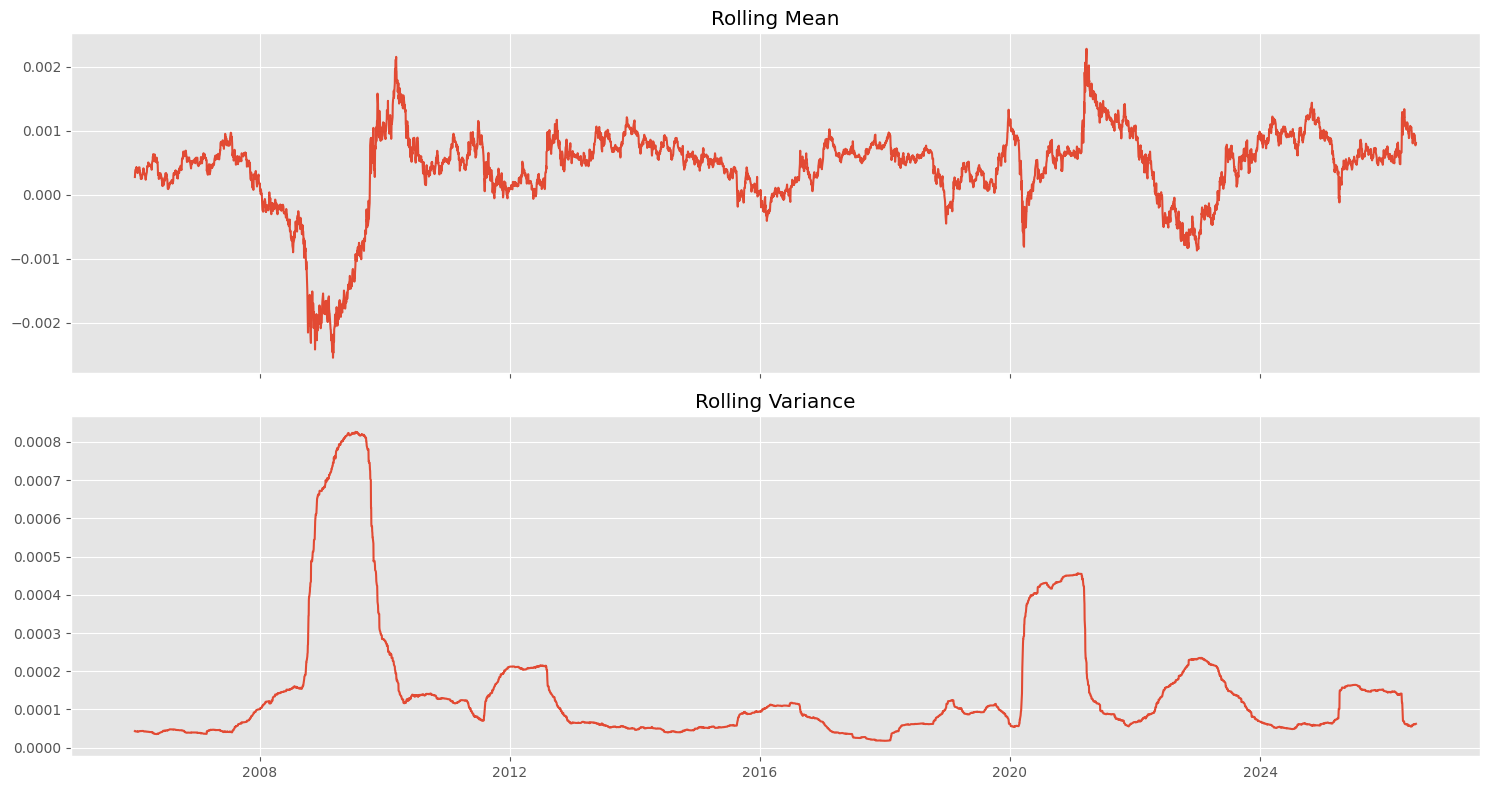

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(15,8), sharex=True)

ax[0].plot(rolling_mean)
ax[0].set_title("Rolling Mean")
ax[0].grid(True)
ax[1].plot(rolling_var)
ax[1].set_title("Rolling Variance")
ax[1].grid(True)
plt.tight_layout()
plt.show()

### **The Three Biggest Lessons from Notebook 1**

1.  **Markets are not IID. Observations are dependent through time.This makes time-series models necessary.**

2. **Markets are not Stationary. Statistical properties evolve. One probability distribution is insufficient.**

3. **The evolution is not random, It reflects changes in the underlying macroeconomic environment. Those hidden environments are what we call market regimes.**

